# **Connect to GEE**

In [ ]:
!pip install -q --upgrade --pre xee
!pip install -q -U geemap

In [ ]:
import ee

In [ ]:
ee.Authenticate()
ee.Initialize(
    project = 'ee-amirhosseinahrari',
    opt_url = 'https://earthengine-highvolume.googleapis.com'
)

# **Study Area**

In [ ]:
import geemap

In [ ]:
map = geemap.Map(basemap = 'SATELLITE')
map

Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', transp…

In [ ]:
roi = map.draw_last_feature.geometry()
roi

ee.Geometry({
  "functionInvocationValue": {
    "functionName": "Feature.geometry",
    "arguments": {
      "feature": {
        "functionInvocationValue": {
          "functionName": "Feature",
          "arguments": {
            "geometry": {
              "functionInvocationValue": {
                "functionName": "GeometryConstructors.Polygon",
                "arguments": {
                  "coordinates": {
                    "constantValue": [
                      [
                        [
                          48.35083,
                          31.034108
                        ],
                        [
                          48.35083,
                          31.648705
                        ],
                        [
                          48.944092,
                          31.648705
                        ],
                        [
                          48.944092,
                          31.034108
                        ],
                        [
                          48.35083,
                          31.034108
                        ]
                      ]
                    ]
                  },
                  "geodesic": {
                    "constantValue": false
                  }
                }
              }
            }
          }
        }
      }
    }
  }
})

# **AOD Image Collection**

In [ ]:
aod = (
    ee.ImageCollection("NOAA/VIIRS/AOD_EDR/V3")
    .filterDate('2023','2026')
    .filterBounds(roi)
    .select('AOD550')
)

In [ ]:
aod.size()

In [ ]:
aod.limit(10)

# **to Xarray**

In [ ]:
from xee import helpers
from shapely.geometry import shape
import xarray as xr

In [ ]:
grid = helpers.fit_geometry(
    geometry = shape(roi.getInfo()),
    grid_crs = 'EPSG:3857',
    grid_scale = (1000, -1000)
)

In [ ]:
ds = xr.open_dataset(
    aod,
    engine = 'ee',
    **grid
)

In [ ]:
ds = ds.sortby('time') * 1

# **Temporal Resampling**

In [ ]:
ds_daily = ds.resample(time = 'D').mean('time')

In [ ]:
ds_mean = ds_daily.mean(dim = 'time')

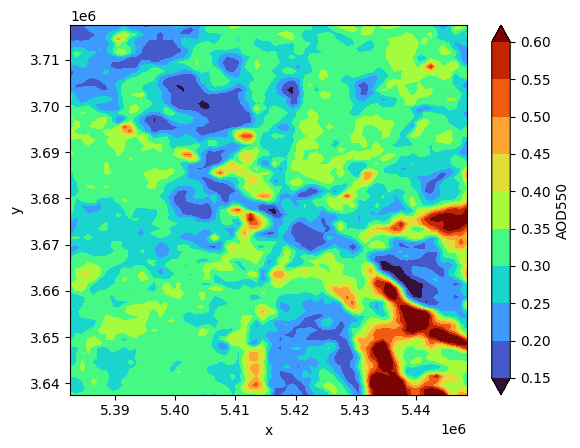

In [ ]:
ds_mean.AOD550.plot.contourf(robust = True, cmap = 'turbo', levels = 10)

In [ ]:
ds_mean2 = ds_daily.mean(dim = ['x','y'])

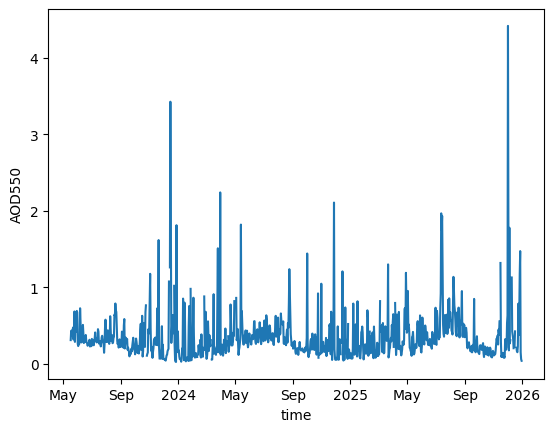

In [ ]:
ds_mean2.AOD550.plot()

# **Frequency Analysis**

In [ ]:
thr = (ds_daily.AOD550 >= 1.0).astype(int)
freq = thr.resample(time = 'YE').sum('time')
obs = thr.resample(time = 'YE').count('time')

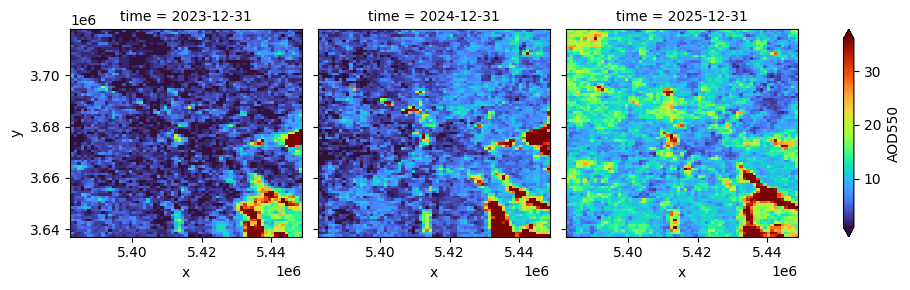

In [ ]:
freq.plot(robust = True, cmap = 'turbo', col = 'time')

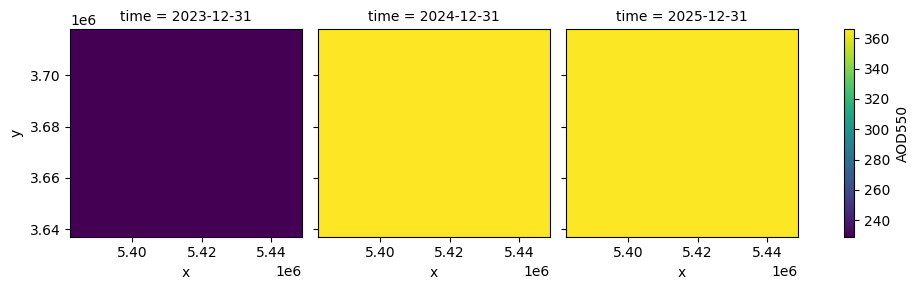

In [ ]:
obs.plot(col = 'time')

In [ ]:
per = freq / obs * 100

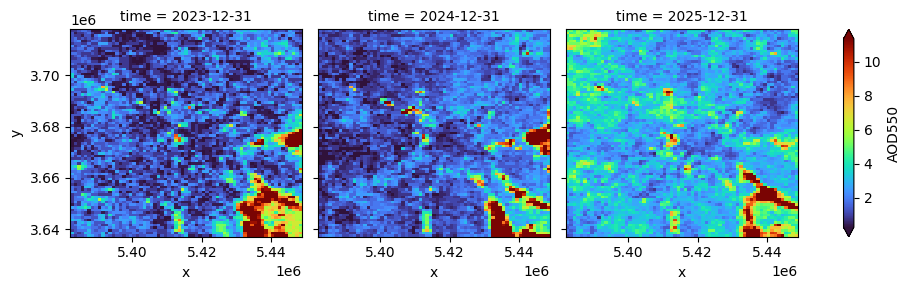

In [ ]:
per.plot(robust = True, col = 'time', cmap = 'turbo')

# **AOD Classification**

In [ ]:
import numpy as np

In [ ]:
cls_thr = [0.2, 0.4, 0.6, 1.0]

ds_cls = np.digitize(
    ds_daily.AOD550.values,
    bins = cls_thr
) + 1

ds_cls = xr.DataArray(
    ds_cls,
    dims = ds_daily.dims,
    coords = ds_daily.coords
)

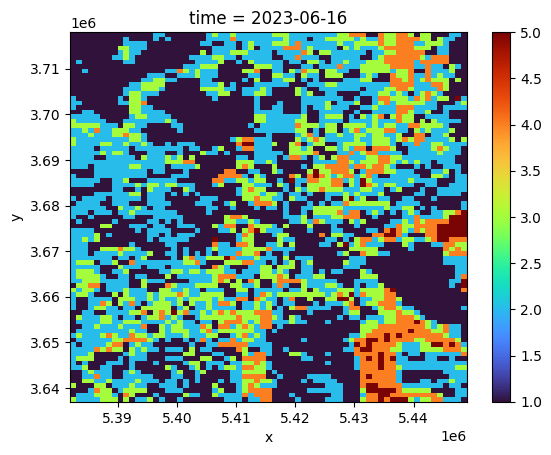

In [ ]:
ds_cls.isel(time = 30).plot(cmap = 'turbo')

In [ ]:
aod_annual = ds_cls.resample(time = 'YE').median('time')

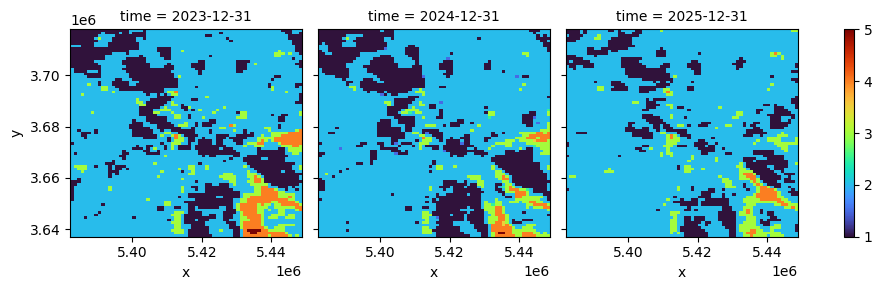

In [ ]:
aod_annual.plot(col = 'time', robust = False, cmap = 'turbo')

In [ ]:
aod_point = ds_cls.sel(
    x = 48.66450795459233,
    y = 31.31364858653831,
    method = 'nearest'
)

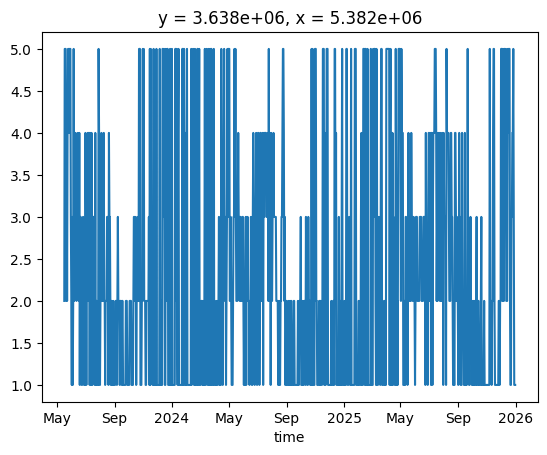

In [ ]:
aod_point.plot()

In [ ]:
df = aod_point.to_dataframe('aod_cls')['aod_cls']
df

,aod_cls
time,
2023-05-17,2
2023-05-18,5
2023-05-19,5
2023-05-20,5
2023-05-21,2
...,...
2025-12-27,5
2025-12-28,3
2025-12-29,1


In [ ]:
df[df >= 4]

,aod_cls
time,
2023-05-18,5
2023-05-19,5
2023-05-20,5
2023-05-22,4
2023-05-24,4
...,...
2025-12-18,5
2025-12-19,5
2025-12-25,4


In [ ]:
df[df == 1]

,aod_cls
time,
2023-06-02,1
2023-06-04,1
2023-06-19,1
2023-06-23,1
2023-06-24,1
...,...
2025-12-21,1
2025-12-22,1
2025-12-29,1
